# 03 · Análise de resultados

Onde cada abordagem acerta, onde erra e quanto custa. Todas as figuras são geradas a partir de `results/runs.jsonl`.

In [1]:
import sys, os, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


In [2]:
from promptlab.runner import load_results
from promptlab.evaluate import results_to_frame, summarize
rows = load_results(ROOT / 'results' / 'runs.jsonl')
df = results_to_frame(rows)
df['config'] = df['model'] + ' · ' + df['strategy']
print(df['config'].unique())

<StringArray>
['baseline:regex · regex']
Length: 1, dtype: str


## Acurácia por campo
Campos como `peso_kg` (toneladas) e `placa_veiculo` (ausente → `null`) separam modelos que *entendem* o documento de modelos que só copiam padrões.

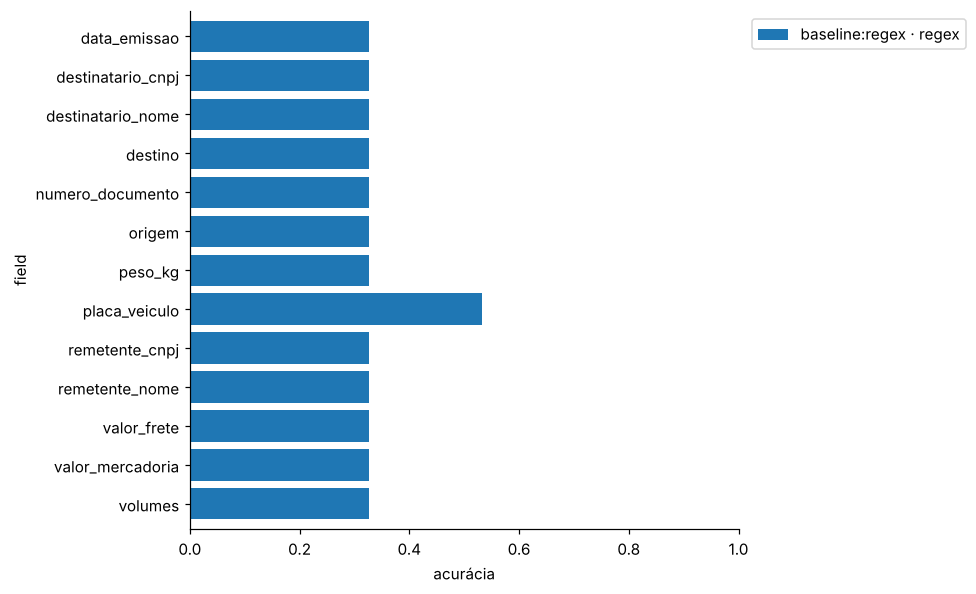

In [3]:
pivot = df.pivot_table(index='field', columns='config', values='correct', aggfunc='mean')
ax = pivot.plot.barh(figsize=(9, 5.5), width=0.8)
ax.set_xlim(0, 1); ax.set_xlabel('acurácia'); ax.invert_yaxis()
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left'); plt.tight_layout(); plt.show()

## Acurácia por estilo de documento

In [4]:
style = df.pivot_table(index='config', columns='style', values='correct', aggfunc='mean')[['estruturado', 'ocr', 'email']]
style.round(3).style.background_gradient(cmap='Greens', vmin=0, vmax=1)

style,estruturado,ocr,email
config,,,
baseline:regex · regex,1.000000,0.030000,0.018000


## Taxonomia de erros
Distingue **omissão** (campo ficou nulo), **erro** (valor errado) e **alucinação** (inventou valor onde o gabarito é nulo). Cada tipo pede uma correção de prompt diferente.

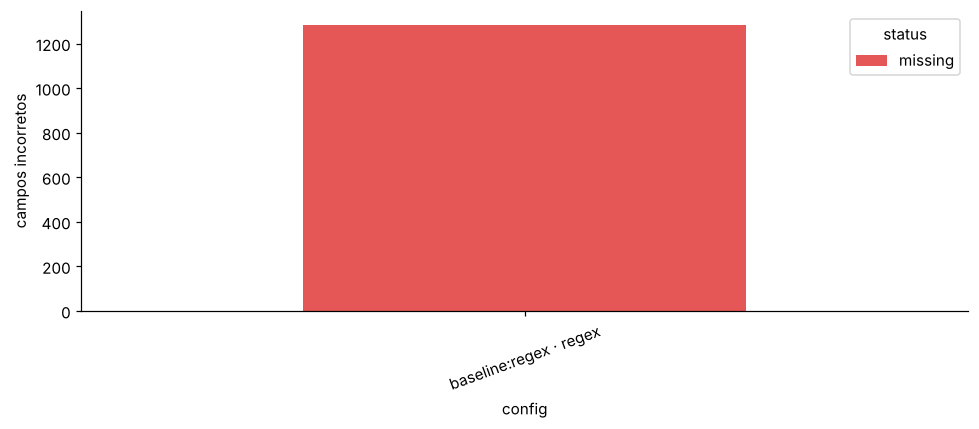

In [5]:
err = df[df.status != 'correct'].groupby(['config', 'status']).size().unstack(fill_value=0)
err.plot.bar(stacked=True, figsize=(9, 4), rot=20, color=['#E45756', '#F58518', '#4C78A8'][:err.shape[1]])
plt.ylabel('campos incorretos'); plt.tight_layout(); plt.show()

## Custo × qualidade
Só há custo para modelos com preço configurado (`PRICING_JSON`). O ponto ideal é o canto superior esquerdo: alta acurácia, baixo custo por 1.000 documentos.

In [6]:
s = summarize(df)
s['config'] = s['model'] + ' · ' + s['strategy']
paid = s.dropna(subset=['cost_per_1k_docs_usd'])
paid = paid[paid.cost_per_1k_docs_usd > 0]
if paid.empty:
    print('Sem execuções pagas com preço configurado ainda — rode o notebook 02 com LAB_MODELS e PRICING_JSON.')
else:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.scatter(paid.cost_per_1k_docs_usd, paid.exact_match, s=80)
    for _, r in paid.iterrows():
        ax.annotate(r.config, (r.cost_per_1k_docs_usd, r.exact_match), fontsize=8, xytext=(5, 5), textcoords='offset points')
    ax.set_xlabel('custo por 1.000 docs (USD)'); ax.set_ylabel('exact match'); ax.set_ylim(0, 1.02); plt.show()

Sem execuções pagas com preço configurado ainda — rode o notebook 02 com LAB_MODELS e PRICING_JSON.


## Conclusões (a preencher com seus resultados)
1. Qual estratégia de prompt trouxe maior ganho por modelo?
2. O CoT compensa o custo extra de tokens de saída?
3. Em qual estilo de documento o LLM mais supera o baseline?
4. Qual a taxa de alucinação em `placa_veiculo`?